In [1]:
!pip install matplotlib

Defaulting to user installation because normal site-packages is not writeable


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [6]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")


In [7]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               str    
 2   title              str    
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           str    
dtypes: bool(1), float64(2), int64(3), str(3)
memory usage: 151.5 MB


In [9]:
df.describe()

,uid,stars,reviews,price,boughtInLastMonth
count,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06
mean,1.370545e+06,2.152836e+00,4.806278e+02,8.924381e+01,2.589699e+01
std,8.160562e+05,2.194865e+00,5.944124e+03,3.456089e+02,2.404837e+02
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,6.589215e+05,0.000000e+00,0.000000e+00,9.990000e+00,0.000000e+00
50%,1.349029e+06,0.000000e+00,0.000000e+00,1.909000e+01,0.000000e+00
75%,2.060686e+06,4.400000e+00,5.900000e+01,4.599000e+01,0.000000e+00
max,2.828593e+06,5.000000e+00,1.356658e+06,1.000000e+05,5.000000e+04


In [14]:
df.describe(include=["object", "string"])

,asin,title,category
count,2443651,2443651,2443651
unique,2222742,2077591,296
top,B0884G1PZ5,OYhmc Portable Pedal Exerc,Sports & Outdoors
freq,7,723,836265


In [16]:
# Part 1 - Understanding Product Categories

## Business Question

#What are the most popular product categories on Amazon UK?

#We begin by exploring the frequency of each product category to identify which categories contain the largest number of listings.

In [17]:
# Frequency table for product categories

category_freq = df["category"].value_counts()

category_freq

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Motorbike Chassis                            107
Alexa Built-In Devices                       107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [18]:
### Top 5 Categories
#To better answer the business question, we display only the five categories with the highest number of listings.

category_freq.head(5)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

### Business Insight

The **Sports & Outdoors** category is by far the largest product category on Amazon UK, with more than **836,000** listings.

The next four categories contain only around **19,000** products each, which is significantly lower. This suggests that the distribution of product categories is highly imbalanced, with one category representing a much larger share of the dataset than the others.



### Bar Chart

A bar chart helps visualize the distribution of product listings across categories.

Since the dataset contains many categories, we display only the top 10 most frequent categories to improve readability.

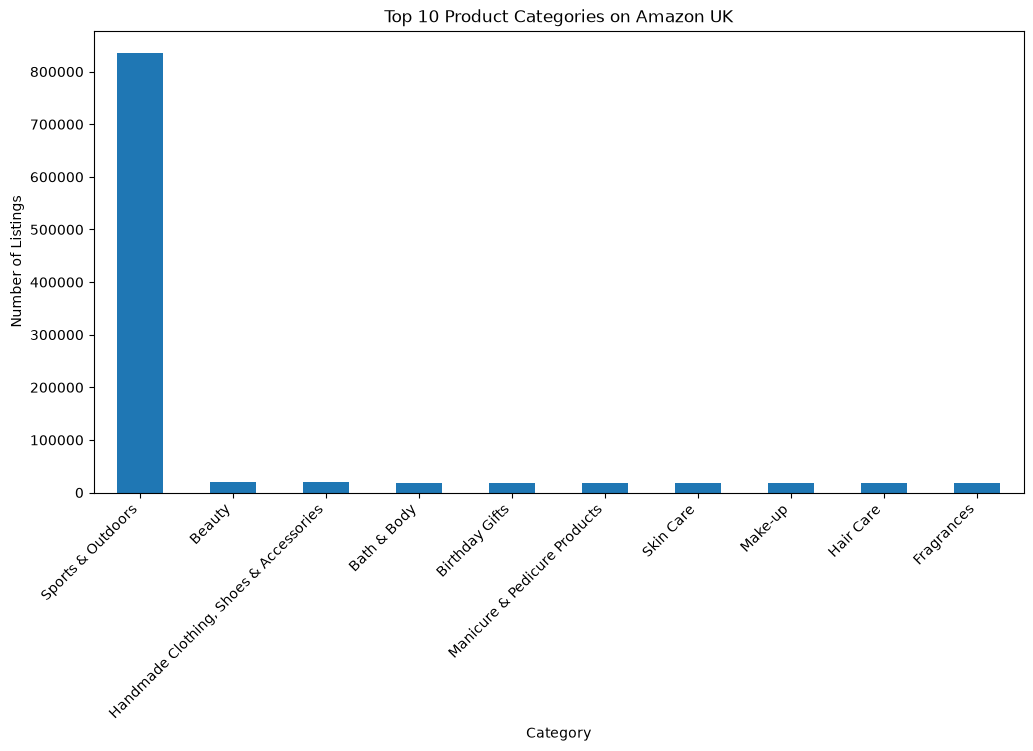

In [19]:
# Top 10 categories
top10_categories = category_freq.head(10)

plt.figure(figsize=(12,6))

top10_categories.plot(kind="bar")

plt.title("Top 10 Product Categories on Amazon UK")
plt.xlabel("Category")
plt.ylabel("Number of Listings")
plt.xticks(rotation=45, ha="right")

plt.show()

In [ ]:
### Bar Chart Without the Dominant Category

#To better compare the remaining categories, we remove the dominant category (**Sports & Outdoors**) from the visualization.

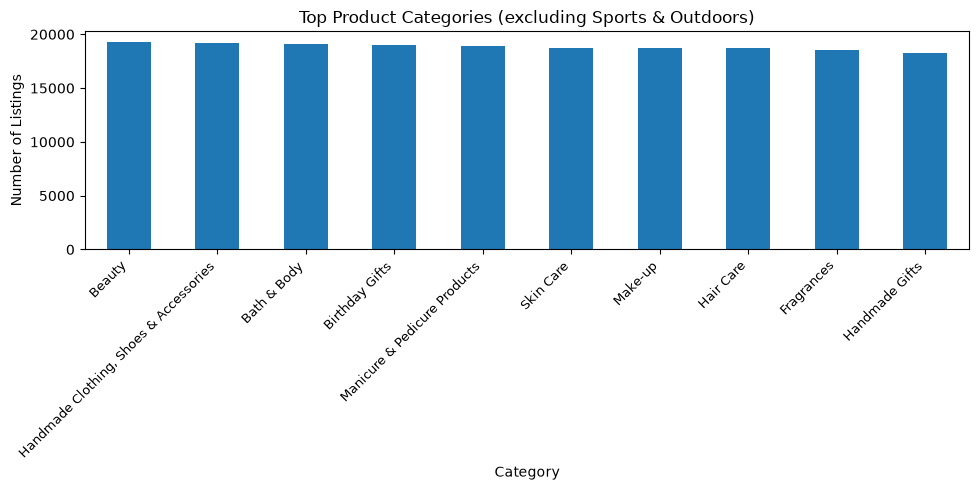

In [21]:
# Remove the dominant category
top10_without_first = category_freq.iloc[1:11]

plt.figure(figsize=(10,5))

top10_without_first.plot(kind="bar")

plt.title("Top Product Categories (excluding Sports & Outdoors)")
plt.xlabel("Category")
plt.ylabel("Number of Listings")
plt.xticks(rotation=45, ha="right", fontsize=9)

plt.tight_layout()

plt.show()

### Pie Chart

A pie chart helps visualize the proportion of products across the most common categories.

To improve readability, we exclude the dominant **Sports & Outdoors** category and focus on the next ten most frequent categories.

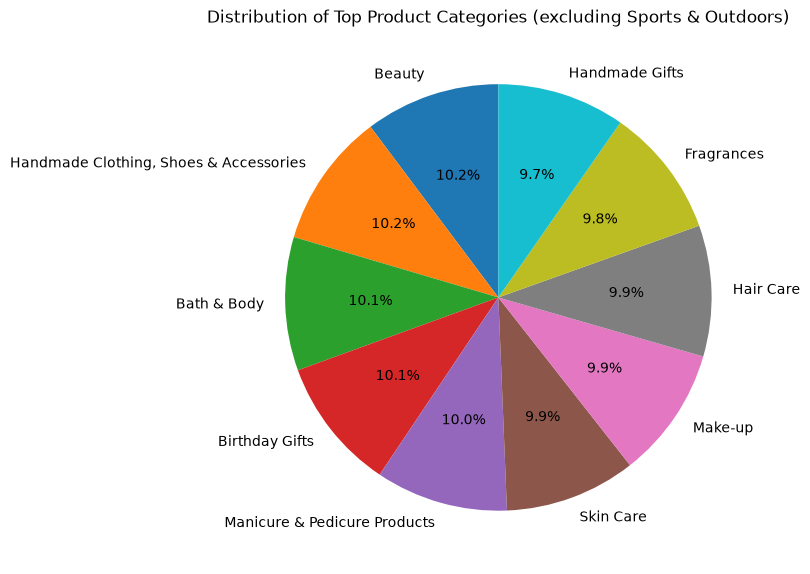

In [22]:
# Pie chart for the top categories (excluding Sports & Outdoors)

plt.figure(figsize=(8,8))

top10_without_first.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribution of Top Product Categories (excluding Sports & Outdoors)")
plt.ylabel("")

plt.tight_layout()

plt.show()

In [ ]:
### Business Insight

#After excluding the Sports & Outdoors category, no category clearly dominates the others. 
#The remaining top categories have a similar number of product listings, indicating a relatively balanced distribution.

# Part 2 - Delving into Product Pricing

## Business Question

How are products priced on Amazon UK?

In this section, we explore the distribution of product prices by calculating measures of central tendency and dispersion. We also use visualizations to identify common price ranges and potential outliers.

In [23]:
### Measures of Centrality

#We calculate the mean, median, and mode of product prices to understand the typical price of products listed on Amazon UK.

# Measures of centrality

price_mean = df["price"].mean()
price_median = df["price"].median()
price_mode = df["price"].mode()[0]

print(f"Mean price: £{price_mean:.2f}")
print(f"Median price: £{price_median:.2f}")
print(f"Mode price: £{price_mode:.2f}")

Mean price: £89.24
Median price: £19.09
Mode price: £9.99


In [25]:
### Business Insight

##The mean, median, and mode provide different perspectives on product pricing.##

#- The **mean** represents the average product price.
#- The **median** represents the middle value.
#- The **mode** is the most frequently occurring price.

#Comparing these measures helps identify whether the price distribution is symmetric or influenced by extremely high-priced products.

In [26]:
### Business Insight

#The average product price is **£89.24**, while the median price is only **£19.09** and the most common price is **£9.99**.

#This large difference suggests that the price distribution is highly right-skewed. 
#A relatively small number of expensive products increase the average price, while most products are sold at much lower prices.

In [27]:
### Measures of Dispersion

#We calculate measures of dispersion to evaluate how much product prices vary across the dataset.

#These statistics help us understand whether prices are concentrated around a typical value or spread over a wide range.

# Measures of dispersion

price_variance = df["price"].var()
price_std = df["price"].std()

price_range = df["price"].max() - df["price"].min()

Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
price_iqr = Q3 - Q1

print(f"Variance: {price_variance:.2f}")
print(f"Standard Deviation: {price_std:.2f}")
print(f"Range: {price_range:.2f}")
print(f"Interquartile Range (IQR): {price_iqr:.2f}")

Variance: 119445.49
Standard Deviation: 345.61
Range: 100000.00
Interquartile Range (IQR): 36.00


In [ ]:
### Business Insight

#The product prices show a very high level of variability.

#Although the total price range is extremely large (£100,000), the interquartile range (IQR) is only £36. This indicates that the middle 50% of products are concentrated within a relatively narrow price range.

#The large standard deviation and variance suggest that a small number of very expensive products increase the overall spread of the data.

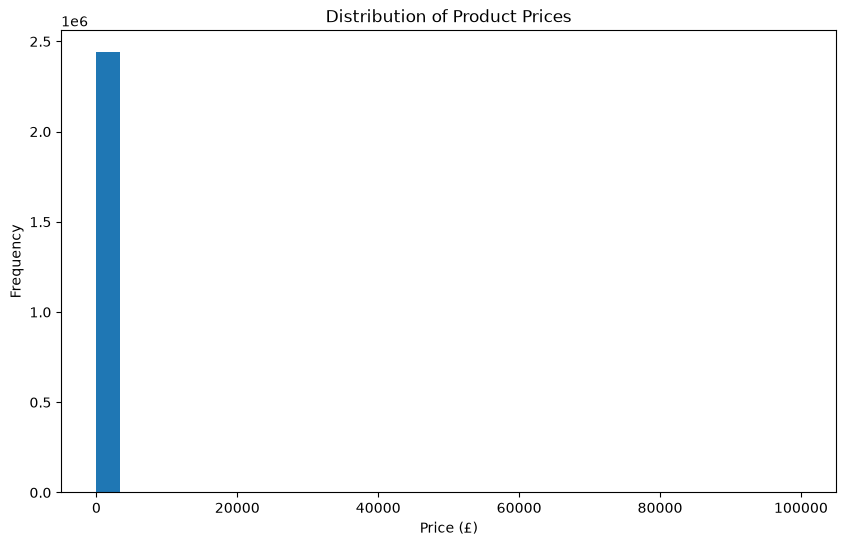

In [28]:
### Histogram

#We use a histogram to visualize the distribution of product prices and identify the most common price ranges.

plt.figure(figsize=(10,6))

plt.hist(df["price"], bins=30)

plt.title("Distribution of Product Prices")
plt.xlabel("Price (£)")
plt.ylabel("Frequency")

plt.show()

In [ ]:
### Business Insight

#The histogram is difficult to interpret because a small number of extremely expensive products stretch the x-axis.

#As a result, the vast majority of products are compressed into a very small area on the left side of the graph, making it impossible to clearly identify the most common price range.

#A better visualization would limit the x-axis or remove extreme outliers to better represent the distribution of most product prices.

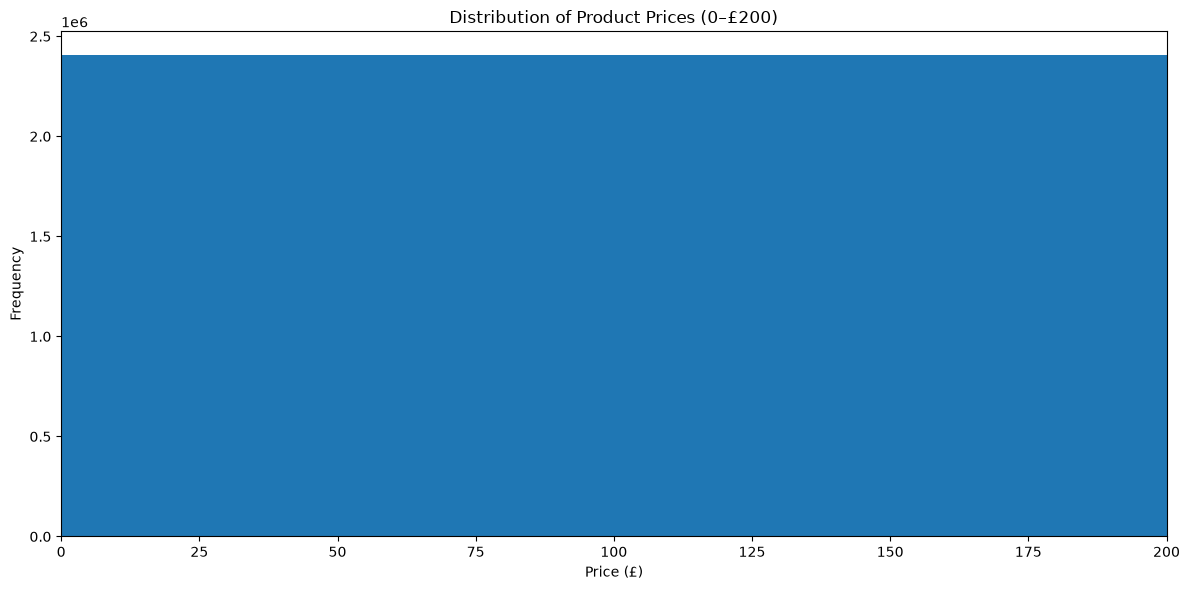

In [30]:
### Improved Histogram

#To better visualize the distribution of the majority of products, we limit the x-axis to £200 while keeping all observations in the dataset.

plt.figure(figsize=(12,6))

plt.hist(df["price"], bins=100)

plt.xlim(0, 200)

plt.title("Distribution of Product Prices (0–£200)")
plt.xlabel("Price (£)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [31]:
df["price"].describe()

count    2.443651e+06
mean     8.924381e+01
std      3.456089e+02
min      0.000000e+00
25%      9.990000e+00
50%      1.909000e+01
75%      4.599000e+01
max      1.000000e+05
Name: price, dtype: float64

In [ ]:
### Improved Histogram

#To better understand the distribution of the majority of products, we focus on products priced at **£50 or less**.

#This reduces the visual distortion caused by a small number of extremely expensive products while preserving the overall distribution of most listings.

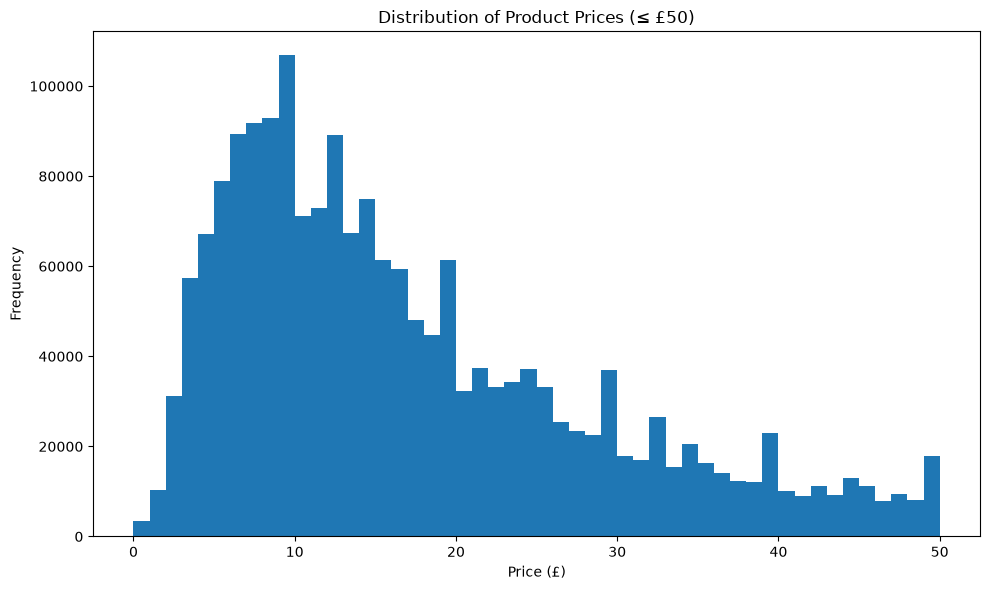

In [32]:
# Focus on the majority of products (prices up to £50)

price_under_50 = df[df["price"] <= 50]

plt.figure(figsize=(10,6))

plt.hist(price_under_50["price"], bins=50)

plt.title("Distribution of Product Prices (≤ £50)")
plt.xlabel("Price (£)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [ ]:
### Business Insight

#After focusing on products priced at £50 or less, the distribution becomes much easier to interpret.

#Most products are priced below £20, with the highest concentration around £10. As prices increase, the number of products gradually decreases, 
#resulting in a right-skewed distribution.

#This confirms that Amazon UK mainly offers low-priced products, while higher-priced items are much less common.

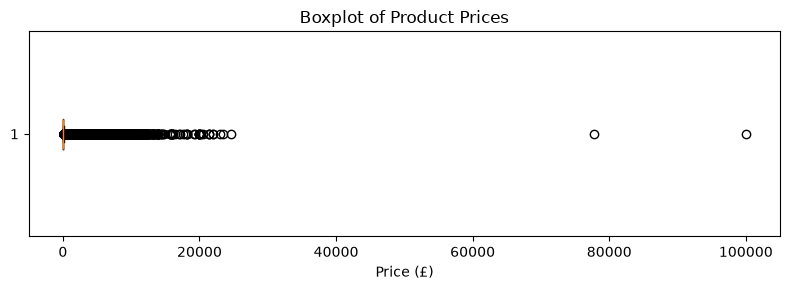

In [34]:
### Boxplot

#A boxplot helps visualize the spread of product prices and identify potential outliers.

plt.figure(figsize=(8,3))

plt.boxplot(df["price"], orientation="horizontal")

plt.title("Boxplot of Product Prices")
plt.xlabel("Price (£)")

plt.tight_layout()
plt.show()

In [ ]:
### Business Insight

#The boxplot reveals a large number of high-price outliers.

#Most products are concentrated within a relatively low price range, while a small number of extremely expensive products extend far beyond the rest of the distribution.

#These outliers explain why the average price is much higher than the median and why the overall distribution is strongly right-skewed.

In [ ]:
### Improved Boxplot

#To better visualize the spread of the majority of product prices, we focus on products priced at £50 or less.

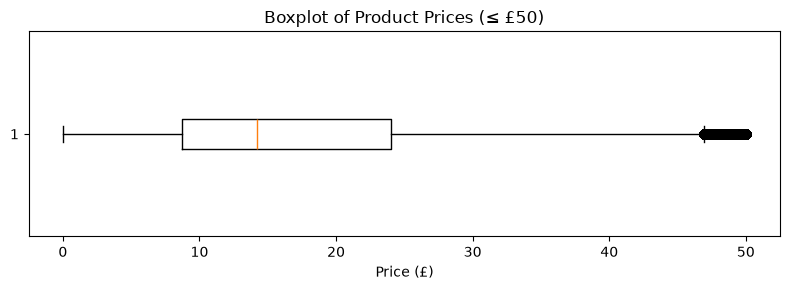

In [35]:
plt.figure(figsize=(8,3))

plt.boxplot(
    df.loc[df["price"] <= 50, "price"],
    orientation="horizontal"
)

plt.title("Boxplot of Product Prices (≤ £50)")
plt.xlabel("Price (£)")

plt.tight_layout()
plt.show()

In [ ]:
### Improved Boxplot

To better visualize the central distribution of product prices, we create a second boxplot focusing on products priced at £50 or less.

This provides a clearer view of the median, quartiles, and overall spread of the majority of products.

## Part 3: Unpacking Product Ratings

### Measures of Centrality

To understand how customers generally rate products on Amazon UK, we calculate the mean, median, and mode of the product ratings.

These measures help identify the typical customer rating and reveal whether ratings tend to cluster around specific values.

In [36]:
# Mean, median and mode of product ratings

mean_rating = df["stars"].mean()
median_rating = df["stars"].median()
mode_rating = df["stars"].mode()[0]

print(f"Mean rating: {mean_rating:.2f}")
print(f"Median rating: {median_rating:.2f}")
print(f"Mode rating: {mode_rating:.2f}")

Mean rating: 2.15
Median rating: 0.00
Mode rating: 0.00


In [37]:
# Number of products with 0-star ratings
zero_ratings = (df["stars"] == 0).sum()

print(f"Products with 0-star ratings: {zero_ratings:,}")
print(f"Percentage: {zero_ratings / len(df) * 100:.2f}%")

Products with 0-star ratings: 1,225,641
Percentage: 50.16%


In [38]:
### Business Insight

#The average product rating is relatively low (2.15 stars), while both the median and mode are 0.

#Further investigation revealed that over 50% of the products have a rating of 0, 
#suggesting that many products may not have received customer ratings yet rather than being poorly rated.

#This highlights the importance of understanding the meaning of the data before drawing conclusions from summary statistics.

In [ ]:
### Distribution of Product Ratings

#To better understand how product ratings are distributed, we create a histogram.

#This visualization helps identify the most common rating values and whether customer ratings are concentrated around specific scores.

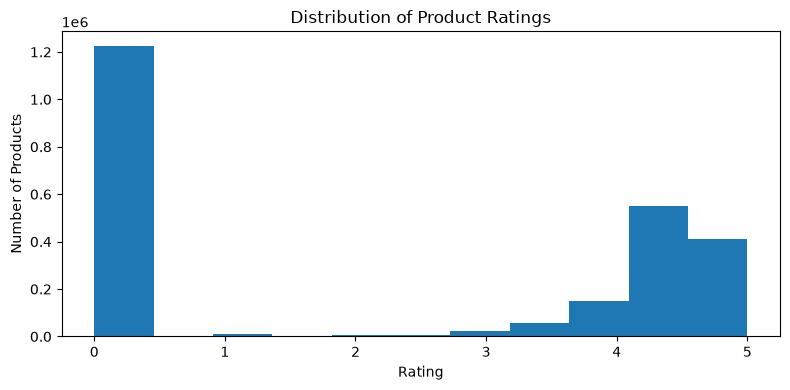

In [39]:
plt.figure(figsize=(8,4))

plt.hist(df["stars"], bins=11)

plt.title("Distribution of Product Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Products")

plt.tight_layout()
plt.show()

In [40]:
### Business Insight

#The histogram reveals two distinct groups of products.

#A large proportion of products have a rating of 0, which likely represents products with no customer ratings rather than poor ratings.

#Among products that have been rated, most receive high ratings between 4 and 5 stars, 
#suggesting that customers generally give positive feedback once a product has been reviewed.

In [41]:
### Measures of Dispersion

#To evaluate the variability of product ratings, we calculate the variance, standard deviation, and interquartile range (IQR).

#These statistics indicate whether customer ratings are consistent across products or highly dispersed.


# Measures of dispersion for product ratings

variance_rating = df["stars"].var()
std_rating = df["stars"].std()
iqr_rating = df["stars"].quantile(0.75) - df["stars"].quantile(0.25)

print(f"Variance: {variance_rating:.2f}")
print(f"Standard deviation: {std_rating:.2f}")
print(f"Interquartile range (IQR): {iqr_rating:.2f}")

Variance: 4.82
Standard deviation: 2.19
Interquartile range (IQR): 4.40


In [42]:
### Business Insight

#The product ratings show considerable variability, with a standard deviation of 2.19 and an interquartile range of 4.40.

#However, this dispersion is largely influenced by the high proportion of products with a rating of 0. 
#As observed in the histogram, many products appear to have no customer ratings, while rated products are mostly concentrated between 4 and 5 stars.

#This demonstrates that summary statistics should always be interpreted alongside data visualizations.

In [45]:
### Skewness and Kurtosis

#To better understand the shape of the rating distribution, we calculate the skewness and kurtosis.

#These metrics help determine whether the distribution is symmetric and whether it contains unusually heavy tails or extreme values.

# Skewness and kurtosis of product ratings

skewness = df["stars"].skew()
kurtosis = df["stars"].kurt()

print(f"Skewness: {skewness:.2f}")
print(f"Kurtosis: {kurtosis:.2f}")

Skewness: 0.08
Kurtosis: -1.93


In [ ]:
### Business Insight

#The rating distribution has a skewness close to zero (0.08), suggesting that it is approximately symmetric overall.

#The negative kurtosis (-1.93) indicates a flatter distribution than a normal distribution, 
#with ratings spread across multiple values rather than concentrated around a single peak.

#Combined with the histogram, these statistics suggest that the data contain two distinct groups: 
#many unrated products (0 stars) and many highly rated products (4–5 stars).

### Overall Findings

Product ratings reveal two distinct groups.

More than half of the products have a rating of 0, which likely indicates products without customer reviews rather than poorly rated products.

Among products that have received ratings, customer feedback is generally very positive, with most ratings concentrated between 4 and 5 stars.

This analysis highlights the importance of combining descriptive statistics with visualizations to correctly interpret the data.